# Part 2: the same method on real fraud data

Part 1 (`fraud_early_warning.ipynb`) used synthetic data, where fraud is loud and a 0.97 PR-AUC is easy. This notebook asks the question an interviewer should ask: **does any of it hold up on real transactions?**

**Data:** IEEE-CIS Fraud Detection (Kaggle, 2019). 590,540 real e-commerce card transactions from Vesta over 6 months, 3.5% fraud. It's the standard real-world fraud benchmark.

**What's different from the synthetic data, and harder:**
- **No card or customer ID.** An account ID has to be reconstructed.
- **Many columns are anonymised or pre-engineered by Vesta**: `C1–C14` (counts, e.g. addresses linked to the card), `D1–D15` (time deltas, e.g. days since previous transaction), `M1–M9` (match flags), `V1–V339` (Vesta's own features).
- **Labels follow a business rule:** once a chargeback is reported, later transactions linked to the same account, email or address are also labelled fraud.

**Same method as Part 1:** audit → point-in-time features in SQL (with leakage tests) → time-based split → alert budget → account-level bootstrap → calibration → error analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression

SEED = 42
FIG = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C_STATIC, C_BEHAV, C_VEND = "#9aa5b1", "#d1495b", "#00798c"
con = duckdb.connect()
con.execute(f"CREATE VIEW f AS SELECT * FROM read_parquet('{ROOT / 'data/ieee_features.parquet'}')")
sql = lambda q: con.sql(q).df()

## 1. Audit

### Is the fraud rate stable over time?

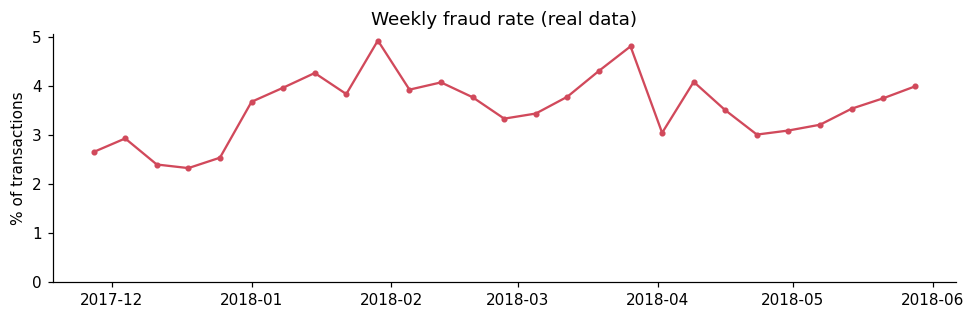

590,540 transactions over 27 weeks; fraud rate 2.3%–4.9% by week


In [2]:
weekly = sql("""
    SELECT date_trunc('week', ts) AS week, count(*) AS txns, avg(is_fraud) * 100 AS fraud_rate_pct
    FROM f GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(weekly.week, weekly.fraud_rate_pct, "o-", ms=3, color=C_BEHAV)
ax.set(title="Weekly fraud rate (real data)", ylabel="% of transactions", ylim=(0, None))
plt.tight_layout(); plt.savefig(FIG / "ieee_weekly_fraud.png", bbox_inches="tight"); plt.show()
print(f"{weekly.txns.sum():,} transactions over {len(weekly)} weeks; fraud rate {weekly.fraud_rate_pct.min():.1f}%–{weekly.fraud_rate_pct.max():.1f}% by week")

Roughly stable after the first few weeks (lower in December, which looks like a holiday-volume effect). No broken periods like the rejected synthetic dataset had.

### How much history does each account have?

Account ID = `card1` (card number fragment) + `addr1` (billing region) + account start day (transaction day − `D1`). This is a widely used approximation, not a ground-truth ID.

In [3]:
sql("""
    WITH a AS (SELECT card_id, count(*) AS n FROM f GROUP BY 1)
    SELECT count(*) AS accounts,
           median(n) AS median_txns_per_account,
           round(avg((n = 1)::INT) * 100, 1) AS pct_accounts_single_txn,
           (SELECT round(avg((n_prior_txn = 0)::INT) * 100, 1) FROM f) AS pct_txns_with_no_history
    FROM a
""")

,accounts,median_txns_per_account,pct_accounts_single_txn,pct_txns_with_no_history
0,217850,1.0,57.5,36.9


**This is the biggest difference from the synthetic data.** There, every card had ~2,000 transactions of history. Here the median account has **one** transaction in six months, and over a third of transactions come with no history at all. Behavioural features have much less to work with.

### How are labels spread within accounts?

In [4]:
lab = sql("""
    WITH x AS (
        SELECT is_fraud,
               max(is_fraud) OVER (PARTITION BY card_id ORDER BY ts, txn_id
                                   ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS earlier_fraud
        FROM f
    )
    SELECT CASE WHEN earlier_fraud = 1 THEN 'after an earlier fraud on the account'
                ELSE 'first fraud on the account' END AS fraud_type,
           count(*) AS frauds
    FROM x WHERE is_fraud = 1 GROUP BY 1
""")
lab["share"] = (lab.frauds / lab.frauds.sum()).round(3)
lab

,fraud_type,frauds,share
0,first fraud on the account,8116,0.393
1,after an earlier fraud on the account,12547,0.607


About 60% of frauds follow an earlier fraud on the same reconstructed account, consistent with the labelling rule. Later I check whether the model only catches these "follow-on" frauds (easy, and already partly handled by chargeback processes) or also the first one.

## 2. Features and split

| Group | Features |
|---|---|
| **Static (named)** | amount, amount cents (odd cents hint at currency conversion), product code, card network and type, email domain, hour, day, distance, device type, has-identity flag |
| **Behavioural (mine, `sql/features_ieee.sql`)** | account velocity (1h/24h/7d), $ in last 24h, number of prior transactions, amount vs account's 30-day average and z-score, hours since previous, new product / email / device for this account, card-range velocity (`card1` in last 1h / 30d) |
| **Vendor (Vesta's)** | C1–C14, D1–D15, M1–M9 |

- `V1–V339` are left out: 339 undocumented, highly redundant columns would dominate the comparison without adding understanding.
- `card1` and `addr1` are used to build the account ID but **not as model inputs**, so the model can't memorise individual accounts.

**Split by time:** train days 0–119, validation days 120–149, test days 150–182.

In [5]:
df = sql("SELECT * FROM f ORDER BY ts, txn_id")
day = (df.ts - df.ts.min()).dt.days
df["date"] = df.ts.dt.normalize()
df["hour"], df["dow"] = df.ts.dt.hour, df.ts.dt.dayofweek
df["amt_cents"] = (df.amt - np.floor(df.amt)).round(3)
top_email = df.email_domain.value_counts().index[:12]
df["email"] = df.email_domain.where(df.email_domain.isin(top_email), "other").fillna("missing")
df["r_email_missing"] = df.recipient_email_domain.isna().astype(int)
df["email_match"] = (df.email_domain == df.recipient_email_domain).astype(int)
for c in ["M1", "M2", "M3", "M5", "M6", "M7", "M8", "M9"]:
    df[c] = df[c].map({"T": 1, "F": 0})
df["M4"] = df.M4.map({"M0": 0, "M1": 1, "M2": 2})
dummies = pd.get_dummies(df[["product", "card_network", "card_type", "email", "device_type"]].fillna("missing"), dtype=int)
df = pd.concat([df, dummies], axis=1)

STATIC = ["log_amt", "amt_cents", "hour", "dow", "dist1", "has_identity", "r_email_missing", "email_match"] + list(dummies.columns)
MINE = ["n_txn_1h", "n_txn_24h", "n_txn_7d", "n_prior_txn", "amt_sum_24h", "acct_avg_amt_30d", "hours_since_prev",
        "amt_vs_30d_avg", "amt_zscore_30d", "new_product_for_acct", "new_email_for_acct", "new_device_for_acct",
        "card1_txn_1h", "card1_txn_30d"]
VENDOR = [f"C{i}" for i in range(1, 15)] + [f"D{i}" for i in range(1, 16)] + [f"M{i}" for i in range(1, 10)]

train, val, test = df[day < 120], df[(day >= 120) & (day < 150)], df[day >= 150]
y_te, amt_te = test.is_fraud.values, test.amt.values
days_val, days_te = val.date.nunique(), test.date.nunique()
pd.DataFrame({s: {"rows": len(d), "frauds": int(d.is_fraud.sum()), "fraud rate": f"{d.is_fraud.mean():.2%}",
                  "txns/day": round(len(d) / d.date.nunique()), "frauds/day": round(d.is_fraud.sum() / d.date.nunique())}
              for s, d in [("train", train), ("validation", val), ("test", test)]}).T

,rows,frauds,fraud rate,txns/day,frauds/day
train,414542,14600,3.52%,3455,122
validation,83571,2850,3.41%,2786,95
test,92427,3213,3.48%,2888,100


## 3. Models

In [6]:
def fit_xgb(features):
    m = xgb.XGBClassifier(n_estimators=1500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.6,
                          min_child_weight=5, eval_metric="aucpr", early_stopping_rounds=50, tree_method="hist",
                          n_jobs=-1, random_state=SEED)
    m.fit(train[features], train.is_fraud, eval_set=[(val[features], val.is_fraud)], verbose=False)
    return m

seen_before_test = set(df.loc[day < 150, "card_id"])
new_acct = ~test.card_id.isin(seen_before_test).values
has_hist = (test.n_prior_txn > 0).values

specs = {"static": STATIC, "static + behavioural (mine)": STATIC + MINE,
         "static + vendor": STATIC + VENDOR, "static + behavioural + vendor": STATIC + MINE + VENDOR}
models, rows = {}, []
for name, feats in specs.items():
    m = fit_xgb(feats)
    pv, pt = m.predict_proba(val[feats])[:, 1], m.predict_proba(test[feats])[:, 1]
    models[name] = (m, feats, pv, pt)
    rows.append({"features": name, "val PR_AUC": average_precision_score(val.is_fraud, pv),
                 "test PR_AUC": average_precision_score(y_te, pt), "test ROC_AUC": roc_auc_score(y_te, pt),
                 "test PR_AUC, new accounts": average_precision_score(y_te[new_acct], pt[new_acct]),
                 "test PR_AUC, accounts with history": average_precision_score(y_te[has_hist], pt[has_hist])})
results = pd.DataFrame(rows).round(3)
results

,features,val PR_AUC,test PR_AUC,test ROC_AUC,"test PR_AUC, new accounts","test PR_AUC, accounts with history"
0,static,0.209,0.185,0.806,0.213,0.167
1,static + behavioural (mine),0.255,0.199,0.837,0.221,0.182
2,static + vendor,0.529,0.491,0.887,0.528,0.449
3,static + behavioural + vendor,0.542,0.488,0.893,0.523,0.445


**The honest result:**

- **My behavioural features barely help on real data**: +0.05 PR-AUC over static features on validation, +0.01 on test, and nothing on top of Vesta's features. On synthetic data the same kind of features lifted PR-AUC from 0.80 to 0.98.
- It isn't only because new accounts have no history. Even on transactions *with* account history, the gain is about 0.015.
- **Vesta's features carry the signal** (0.19 → 0.49). The likely reason: they are computed over Vesta's full network and history (e.g. how many addresses or cards are linked to this account, days since the account's previous activity anywhere), while mine only see six months of one merchant's data through a reconstructed ID.

Lesson: on real data, **where history is recorded matters more than how cleverly you engineer it**. A company's own feature store, not a 6-month extract, is where behavioural features pay off.

In [7]:
best_name = "static + behavioural + vendor"
model, feats, p_val, p_te = models[best_name]
_, _, p_val_sb, p_te_sb = models["static + behavioural (mine)"]

## 4. Alert budget

About 100 frauds happen per day in the test period, among ~2,900 transactions. Assume analysts can review **100 alerts a day**.

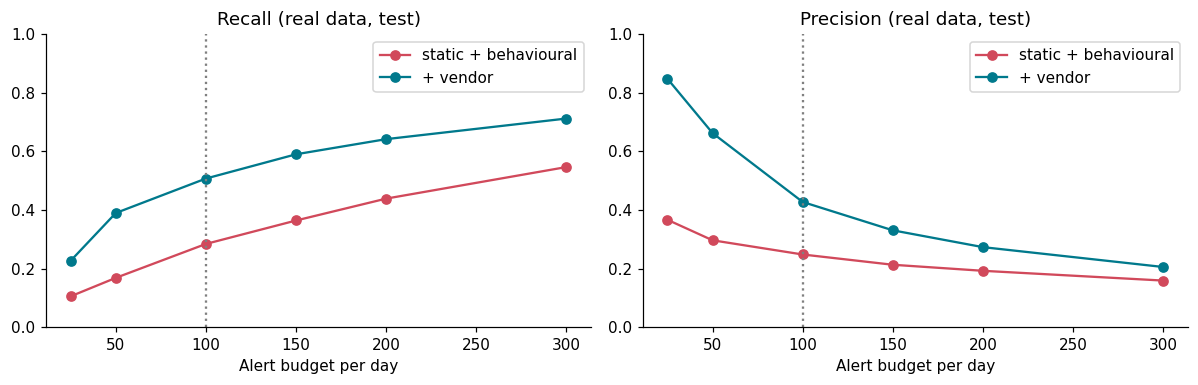

recall                      precision                       \
model      + vendor static + behavioural  + vendor static + behavioural   
budget/day                                                                
25            0.227                0.106     0.848                0.366   
50            0.390                0.168     0.662                0.297   
100           0.507                0.284     0.427                0.248   
150           0.590                0.364     0.331                0.213   
200           0.642                0.439     0.273                0.192   
300           0.712                0.547     0.205                0.159   

           actual/day                       
model        + vendor static + behavioural  
budget/day                                  
25             26.875               28.906  
50             59.062               57.000  
100           119.188              115.000  
150           179.219              171.594  
200           235.875              228.969  
300           348.031              344.938

In [8]:
BUDGET = 100

def threshold_for_budget(scores, n_days, per_day):
    return np.sort(scores)[::-1][int(per_day * n_days) - 1]

curve = []
for b in [25, 50, 100, 150, 200, 300]:
    for name, pv, pt in [("static + behavioural", p_val_sb, p_te_sb), ("+ vendor", p_val, p_te)]:
        fl = pt >= threshold_for_budget(pv, days_val, b)
        curve.append({"budget/day": b, "model": name, "actual/day": fl.sum() / days_te,
                      "precision": precision_score(y_te, fl), "recall": recall_score(y_te, fl)})
curve = pd.DataFrame(curve)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, col in [("static + behavioural", C_BEHAV), ("+ vendor", C_VEND)]:
    c = curve[curve.model == name]
    axes[0].plot(c["budget/day"], c.recall, "o-", color=col, label=name)
    axes[1].plot(c["budget/day"], c.precision, "o-", color=col, label=name)
for ax, t in zip(axes, ["Recall (real data, test)", "Precision (real data, test)"]):
    ax.axvline(BUDGET, ls=":", c="grey"); ax.set(xlabel="Alert budget per day", title=t, ylim=(0, 1)); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "ieee_budget_curve.png", bbox_inches="tight"); plt.show()
curve.pivot(index="budget/day", columns="model", values=["recall", "precision", "actual/day"]).round(3)

**The budget overshoots on real data:** a threshold set for 100/day on validation produces about 119/day on test. Transaction volume and the score distribution both shift a little between periods. On synthetic data the same method held within budget. This is exactly what the alert-volume alarm recommended in Part 1 is for; here it would fire in the first week.

## 5. Test results at 100 alerts/day, with account-level bootstrap

In [9]:
t_b = threshold_for_budget(p_val, days_val, BUDGET)
flag = p_te >= t_b
per_acct = pd.DataFrame({"acct": test.card_id.values, "tp": flag & (y_te == 1), "fp": flag & (y_te == 0),
                         "pos": y_te == 1}).groupby("acct").sum()
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    s = per_acct.iloc[rng.integers(0, len(per_acct), len(per_acct))].sum()
    boot.append({"precision": s.tp / (s.tp + s.fp), "recall": s.tp / s.pos})
boot = pd.DataFrame(boot)
real_summary = pd.DataFrame({
    "value": {"alerts/day": flag.sum() / days_te, "precision": precision_score(y_te, flag), "recall": recall_score(y_te, flag),
              "frauds caught": int((flag & (y_te == 1)).sum()), "false alarms": int((flag & (y_te == 0)).sum()),
              "frauds missed": int((~flag & (y_te == 1)).sum()),
              "fraud $ caught share": amt_te[flag & (y_te == 1)].sum() / amt_te[y_te == 1].sum()},
    "CI_low": {"precision": boot.precision.quantile(.025), "recall": boot.recall.quantile(.025)},
    "CI_high": {"precision": boot.precision.quantile(.975), "recall": boot.recall.quantile(.975)},
})
real_summary.round(3)

,value,CI_low,CI_high
alerts/day,119.188,NaN,NaN
precision,0.427,0.394,0.459
recall,0.507,0.472,0.541
frauds caught,1630.000,NaN,NaN
false alarms,2184.000,NaN,NaN
frauds missed,1583.000,NaN,NaN
fraud $ caught share,0.451,NaN,NaN


### Does it catch the first fraud, or only the follow-ons?

Follow-on frauds (after an earlier fraud on the same account) are partly an artefact of the labelling rule, and a chargeback process would block many of them anyway. The first fraud on an account is what matters.

In [10]:
earlier = df.groupby("card_id").is_fraud.transform(lambda s: s.shift().fillna(0).cummax()).loc[test.index].values == 1
first_mask, follow_mask = (y_te == 1) & ~earlier, (y_te == 1) & earlier
keep = ~follow_mask
pd.DataFrame({
    "frauds": [first_mask.sum(), follow_mask.sum()],
    "recall at 100/day": [flag[first_mask].mean(), flag[follow_mask].mean()],
}, index=["first fraud on account", "follow-on fraud"]).round(3).assign(
    note=[f"PR-AUC with follow-ons removed: {average_precision_score(y_te[keep], p_te[keep]):.3f}", ""])

,frauds,recall at 100/day,note
first fraud on account,1198,0.567,PR-AUC with follow-ons removed: 0.411
follow-on fraud,2015,0.472,


The model catches first frauds at least as well as follow-ons, so it isn't just exploiting the labelling rule.

## 6. Calibration and expected-loss ranking (repeated from Part 1)

In [11]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val, val.is_fraud)
p_te_cal = iso.predict(p_te)
flag_el = (p_te_cal * amt_te) >= threshold_for_budget(iso.predict(p_val) * val.amt.values, days_val, BUDGET)
pd.DataFrame({
    "raw": {"Brier": brier_score_loss(y_te, p_te), "mean predicted": p_te.mean()},
    "calibrated": {"Brier": brier_score_loss(y_te, p_te_cal), "mean predicted": p_te_cal.mean()},
    "actual": {"Brier": np.nan, "mean predicted": y_te.mean()},
}).round(4)

,raw,calibrated,actual
Brier,0.0234,0.0236,NaN
mean predicted,0.0333,0.0373,0.0348


**Calibration isn't needed here, and checking showed that.** Without class weights, raw scores already average close to the real fraud rate, and isotonic calibration doesn't improve the Brier score. In Part 1 it halved the error, because class weights had inflated the scores. Same check, opposite conclusion: worth running, not worth assuming.

In [12]:
def ops(fl):
    return {"precision": precision_score(y_te, fl), "recall": recall_score(y_te, fl),
            "frauds missed": int((~fl & (y_te == 1)).sum()), "fraud $ missed": amt_te[~fl & (y_te == 1)].sum()}
pd.DataFrame({"rank by probability": ops(flag), "rank by expected $ loss": ops(flag_el)}).round(3)

,rank by probability,rank by expected $ loss
precision,0.427,0.294
recall,0.507,0.326
frauds missed,1583.000,2164.000
fraud $ missed,267697.547,184831.784


The same trade-off as Part 1, sharper: ranking by expected loss cuts missed fraud value by about 30%, but recall drops from 0.51 to 0.33. Still a business decision.

## 7. What does the real model miss?

In [13]:
missed, caught = test[(y_te == 1) & ~flag], test[(y_te == 1) & flag]
by_product = pd.DataFrame({
    "frauds": test[y_te == 1]["product"].value_counts(),
    "recall": test[y_te == 1].assign(c=flag[y_te == 1]).groupby("product").c.mean(),
    "fraud rate": test.groupby("product").is_fraud.mean(),
}).sort_values("frauds", ascending=False)
print("Recall by product code:")
print(by_product.round(3).to_string())
pd.DataFrame({
    "caught": [len(caught), caught.amt.median(), caught.has_identity.mean(), (caught.n_prior_txn == 0).mean()],
    "missed": [len(missed), missed.amt.median(), missed.has_identity.mean(), (missed.n_prior_txn == 0).mean()],
}, index=["frauds", "median amount $", "share with device/identity data", "share with no account history"]).round(2)

Recall by product code:
         frauds  recall  fraud rate
product                            
W          1337   0.212       0.018
C          1320   0.769       0.135
R           221   0.733       0.051
H           170   0.576       0.064
S           165   0.436       0.054


,caught,missed
frauds,1630.00,1583.00
median amount $,54.22,77.22
share with device/identity data,0.81,0.33
share with no account history,0.32,0.24


**The misses are concentrated in one place:** product `W`, the largest product line (about 40% of test frauds), where recall is only about 0.21. Missed frauds mostly have **no device/identity data** (33% vs 81% for caught frauds). So the gap is data coverage: when Vesta didn't capture the device, the model has little to go on. That's a concrete ask for a real team: improve device capture on product W, or build a separate model for it.

## 8. SHAP: what drives the real model

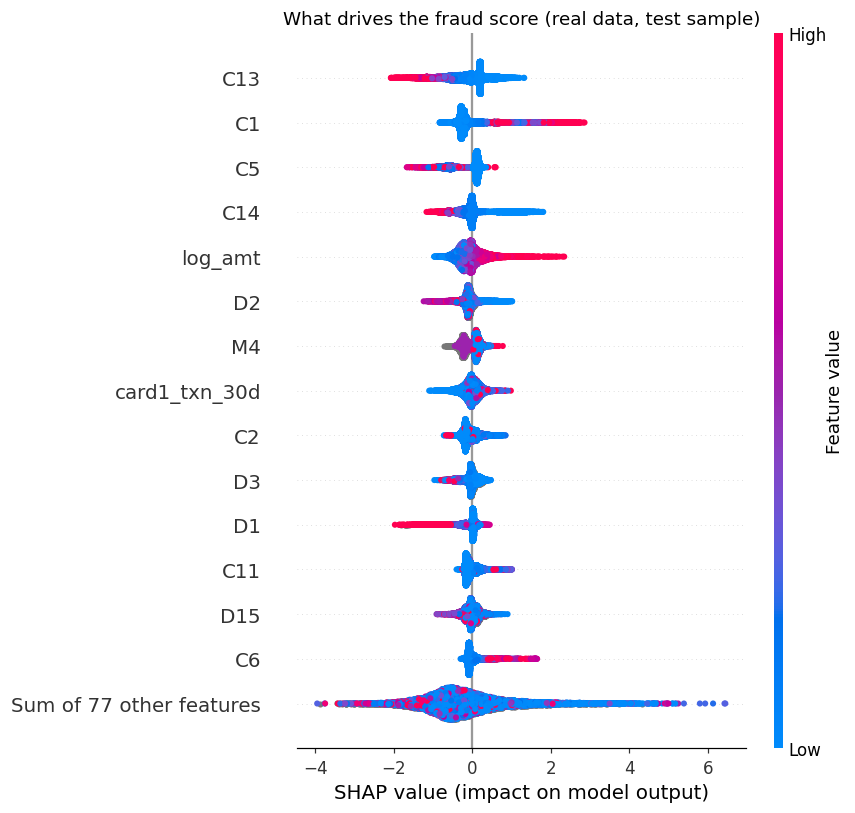

Share of total |SHAP| by feature group:
static                0.25
behavioural (mine)    0.11
vendor                0.64


In [14]:
explainer = shap.TreeExplainer(model)
idx = np.union1d(rng.choice(len(test), 15000, replace=False), np.flatnonzero(y_te == 1))
sv = explainer(test.iloc[idx][feats])
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("What drives the fraud score (real data, test sample)")
plt.tight_layout(); plt.savefig(FIG / "ieee_shap_beeswarm.png", bbox_inches="tight"); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=feats)
shares = pd.Series({"static": imp[STATIC].sum(), "behavioural (mine)": imp[MINE].sum(), "vendor": imp[VENDOR].sum()})
print("Share of total |SHAP| by feature group:"); print((shares / shares.sum()).round(2).to_string())

## 9. Synthetic vs real: what transferred?

| | Synthetic (Part 1) | Real (this notebook) |
|---|---|---|
| Best test PR-AUC | 0.97 | 0.49 |
| Precision / recall at the alert budget | 0.76 / 0.96 | 0.43 / 0.51 |
| Did the budget hold on test? | Yes (12.7 vs 15/day) | No (119 vs 100/day) |
| Gain from my behavioural features (test PR-AUC) | +0.22 (0.74 → 0.97) | +0.01 (0.185 → 0.199); none on top of vendor features |
| Median history per card/account | ~2,000 transactions | 1 transaction |
| Calibration needed? | Yes (class weights inflated scores) | No |
| Catches first fraud of an episode? | 87% of stolen cards on 1st txn | Recall 0.57 on first frauds vs 0.47 on follow-ons |

**Transferred:** the audit, point-in-time features with leakage tests, time-based split, budget-based threshold, account-level bootstrap, calibration check, the first-vs-follow-on analysis.

**Did not transfer:** the size of the behavioural feature gain, and the headline scores. Real fraud is quieter, history is thinner, and the strongest signals live in the payment company's own network-wide features.

**What I'd do next with access to a real feature store:** rebuild the behavioural features on full account history (years, all merchants), add network features (cards per device, accounts per email), and model the label delay explicitly.